<a href="https://colab.research.google.com/github/ardiyanto-ops/Tugas-Praktikum-Machine-Learning/blob/main/bab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

In [ ]:
from google.colab import files
uploaded = files.upload()
PATH = list(uploaded.keys())[0]
df = pd.read_csv(PATH)

print("Ukuran data :", df.shape)
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Ukuran data : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# 1) customerID hanya identitas, tidak dipakai
df = df.drop(columns=["customerID"])

# 2) TotalCharges bertipe teks (ada spasi kosong) -> ubah ke angka
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
df = df.dropna()

# 3) Target Churn: Yes/No -> 1/0
y = (df["Churn"] == "Yes").astype(int).values

# 4) Fitur: kolom kategorikal di-encode dengan one-hot
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
X = X.astype(float).values

print("Jumlah fitur setelah encoding:", X.shape[1])
print("Distribusi kelas:", np.bincount(y))

Missing TotalCharges: 11
Jumlah fitur setelah encoding: 30
Distribusi kelas: [5163 1869]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, random_state=42, stratify=y)
print("Proporsi kelas train:",
      np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :",
      np.bincount(y_test) / len(y_test))

Proporsi kelas train: [0.73422222 0.26577778]
Proporsi kelas test : [0.73418621 0.26581379]


In [ ]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train,
    cv=5, train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy")
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

In [ ]:
print("Skor train pada ukuran data terbesar :",
      round(train_mean[-1], 3))
print("Skor validasi pada ukuran data terbesar:",
      round(val_mean[-1], 3))
print("Gap (indikasi overfitting jika besar)   :",
      round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar : 0.798
Skor validasi pada ukuran data terbesar: 0.791
Gap (indikasi overfitting jika besar)   : 0.008


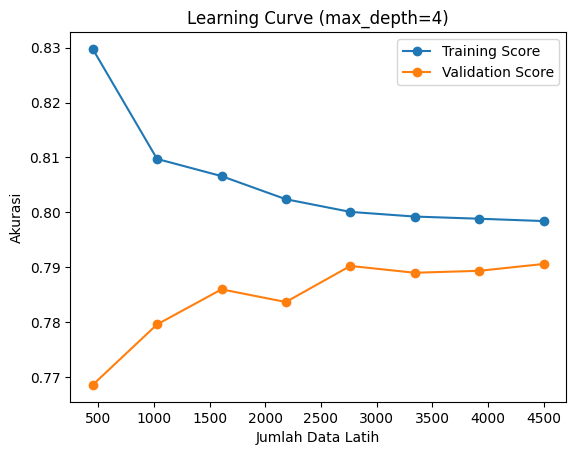

In [ ]:
plt.plot(train_sizes, train_mean, 'o-',
         label='Training Score')
plt.plot(train_sizes, val_mean, 'o-',
         label='Validation Score')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve (max_depth=4)')
plt.legend()
plt.show()

In [ ]:
for depth in [1, 4, None]:
    model = DecisionTreeClassifier(max_depth=depth,
                                   random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=5, train_sizes=np.linspace(0.1, 1.0, 6))
    print(f"max_depth={depth}: "
          f"train={train_scores.mean():.3f}, "
          f"val={val_scores.mean():.3f}")

max_depth=1: train=0.740, val=0.733
max_depth=4: train=0.806, val=0.783
max_depth=None: train=0.999, val=0.727
